# [9660] Decision Tree 1
Data file:
* sklearn : iris

### Import libraries

In [1]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.tree import export_graphviz
import matplotlib.pyplot as plt
import seaborn as sns
import cv2



### Load data

In [2]:
iris = load_iris()

In [3]:
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['species'] = iris.target
df.shape

(150, 5)

### Explore data

In [4]:
iris.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])

In [5]:
print(iris.DESCR)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

In [6]:
iris.feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

In [7]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [8]:
df.head(100)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
95,5.7,3.0,4.2,1.2,1
96,5.7,2.9,4.2,1.3,1
97,6.2,2.9,4.3,1.3,1
98,5.1,2.5,3.0,1.1,1


### Separate independent and dependent variables

In [9]:
# Setup independent and dependent variables
X = df.drop(['species'], axis = 1)
y = df['species']

In [10]:
y

,species
0,0
1,0
2,0
3,0
4,0
...,...
145,2
146,2
147,2
148,2


### Set global variable

In [11]:
global RANDOM_STATE
RANDOM_STATE=42

### Split data into training and test sets

In [12]:
# Split training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

### Train model

In [13]:
# Fit a DecisionTreeClassifier model
tree_1 = DecisionTreeClassifier(random_state=RANDOM_STATE)
tree_1.get_params()

{'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': 42,
 'splitter': 'best'}

In [14]:
tree_1.fit(X_train, y_train)
tree_1.get_depth()

6

### Evaluate model

In [15]:
# Predict using the test set
y_pred = tree_1.predict(X_test)

In [16]:
# Print model accuracy score
accuracy_score_1 = accuracy_score(y_test, y_pred)
print(f"Accuracy = {round((accuracy_score_1 * 100), 4)}%")

Accuracy = 100.0%


In [17]:
iris.feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

In [18]:
tree_1.feature_importances_

array([0.        , 0.01667014, 0.90614339, 0.07718647])

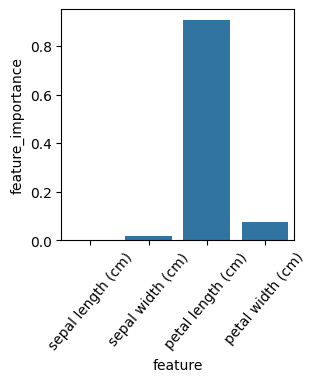

In [19]:
# Create new dataframe to display feature importances
df2 = pd.DataFrame(zip(iris.feature_names, tree_1.feature_importances_),
                   columns=['feature', 'feature_importance'])

fig = plt.figure(figsize = (3, 3))
sns.barplot(data=df2, x='feature', y='feature_importance')
plt.xticks(rotation = 50)
plt.show()

### Visualize model output

In [20]:
# Visualize decision tree. Create dot file.
dot_data=export_graphviz(tree_1, out_file =None,
    feature_names = iris.feature_names,
    class_names = iris.target_names,
    filled = True,
)

In [21]:
import graphviz

In [22]:
graph=graphviz.Source(dot_data,format="png")

In [23]:
# types of Y.

#### why the top sample is 120.. training dataset= 150*80%=120

In [24]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [25]:
40/120

0.3333333333333333

In [26]:
41/120

0.3416666666666667

In [27]:
39/120

0.325

In [28]:
0.3333333*(1-0.3333333)+0.34167*(1-0.34167)+0.325*(1-0.325)

0.66652882221111

In [29]:
40+41+39

120

In [30]:
40/40

1.0

In [31]:
0/40

0.0

In [32]:
1*(1-1)+0*(1-0)+0*(1-0)

0

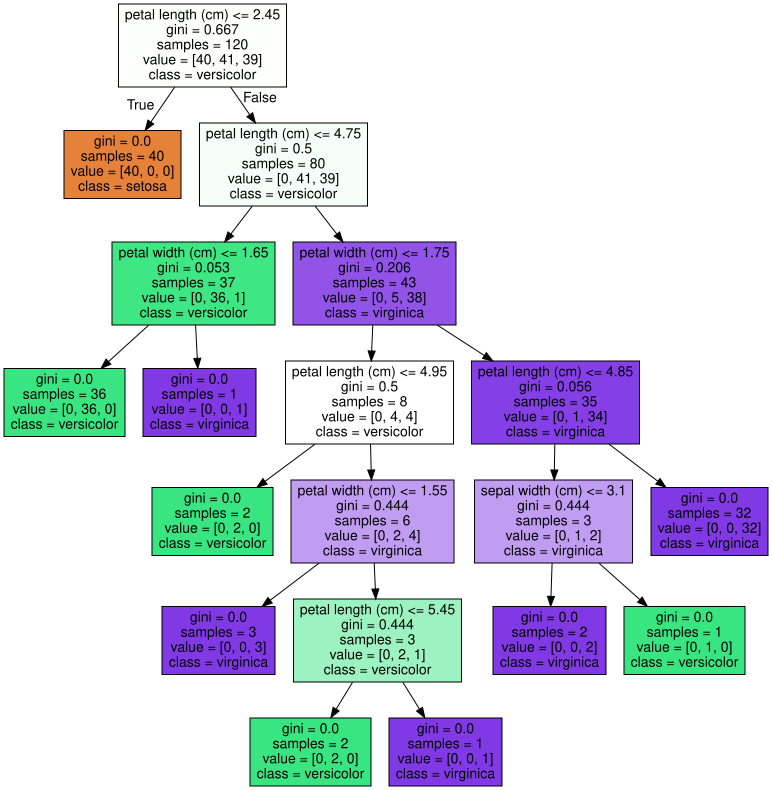

In [33]:
graph

### Train model with different hyperparameters

DecisionTreeClassifer():

In [34]:
# Fit a DecisionTreeClassifier model with a different max_depth value
tree_2 = DecisionTreeClassifier(max_depth=4, criterion='gini', min_samples_split=5, random_state=RANDOM_STATE)
tree_2.get_params()

{'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': 4,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 5,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': 42,
 'splitter': 'best'}

In [35]:
tree_2.fit(X_train, y_train)
tree_2.get_depth()

4

### Evaluate model

In [36]:
# Predict using the test set
y_pred = tree_2.predict(X_test)

In [37]:
# Print model accuracy score
accuracy_score_1 = accuracy_score(y_test, y_pred)
print(f"Accuracy = {round((accuracy_score_1 * 100), 4)}%")

Accuracy = 100.0%


In [38]:
iris.feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

In [39]:
tree_2.feature_importances_

array([0.       , 0.       , 0.9362979, 0.0637021])

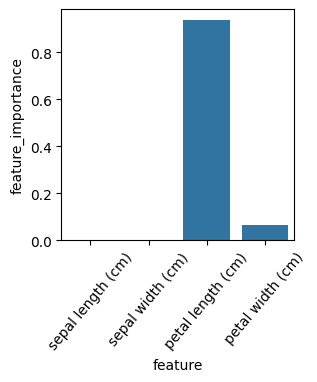

In [40]:
# Create new dataframe to display feature importances
df2 = pd.DataFrame(zip(iris.feature_names, tree_2.feature_importances_),
                   columns=['feature', 'feature_importance'])

fig = plt.figure(figsize = (3, 3))
sns.barplot(data=df2, x='feature', y='feature_importance')
plt.xticks(rotation = 50)
plt.show()

### Visualize model output

In [41]:
# Visualize decision tree. Create dot file.
dot_data2=export_graphviz(tree_2, out_file =None,
    feature_names = iris.feature_names,
    class_names = iris.target_names,
    filled = True,
)

In [42]:
graph2=graphviz.Source(dot_data2,format="png")

In [43]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

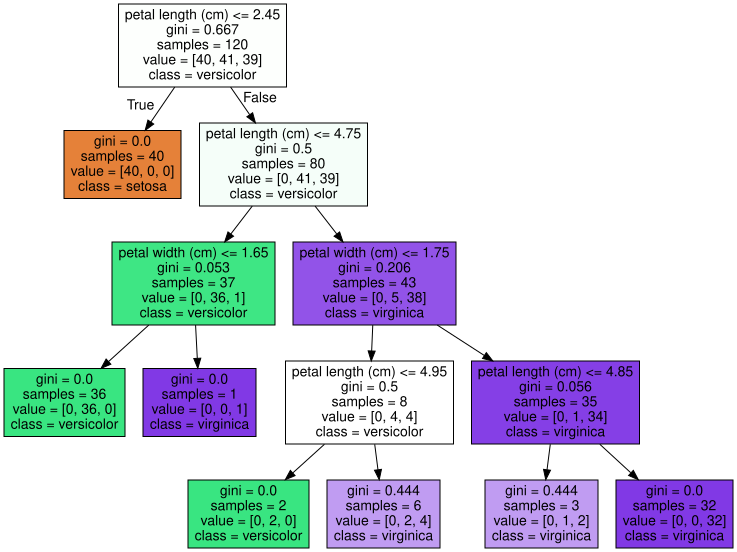

In [44]:
graph2

# [9660] Decision Tree 2 - Hyperparameter Tuning
Data file:
* https://raw.githubusercontent.com/vjavaly/Baruch-CIS-9660/main/data/heart_disease_1.csv

In [45]:
from datetime import datetime
print(f'Run time: {datetime.now().strftime("%D %T")}')

Run time: 11/11/26 21:23:19


### Import libraries

In [46]:
import numpy as np
import pandas as pd
from pprint import pprint
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV

### Load data

Dataset by Heart Disease UCI:

Dataset source: https://archive.ics.uci.edu/ml/datasets/Heart+Disease

Dataset columns:
* age: The person’s age in years
* sex: The person’s sex (1 = male, 0 = female)
* cp: chest pain type
  * Value 0: asymptomatic
  * Value 1: atypical angina
  * Value 2: non-anginal pain
  * Value 3: typical angina
* trestbps: The person’s resting blood pressure (mm Hg on admission to the hospital)
* chol: The person’s cholesterol measurement in mg/dl
* fbs: The person’s fasting blood sugar (> 120 mg/dl, 1 = true; 0 = false)
* restecg: resting electrocardiographic results
  * Value 0: showing probable or definite left ventricular hypertrophy by Estes’ criteria
  * Value 1: normal
  * Value 2: having ST-T wave abnormality (T wave inversions and/or ST elevation or depression of > 0.05 mV)
* thalach: The person’s maximum heart rate achieved
* exang: Exercise induced angina (1 = yes; 0 = no)
* oldpeak: ST depression induced by exercise relative to rest (‘ST’ relates to positions on the ECG plot. See more here)
* slope: the slope of the peak exercise ST segment
  * 0: downsloping
  * 1: flat
  * 2: upsloping
* ca: The number of major vessels (0–3)
* thal: A blood disorder called thalassemia Value 0: NULL (dropped from the dataset previously
  * Value 1: fixed defect (no blood flow in some part of the heart)
  * Value 2: normal blood flow
  * Value 3: reversible defect (a blood flow is observed but it is not normal)
* target: Heart disease (1 = no, 0= yes)

In [47]:
df = pd.read_csv('https://raw.githubusercontent.com/vjavaly/Baruch-CIS-9660/main/data/heart_disease_1.csv')

### Examine data

In [48]:
df.shape

(303, 14)

In [49]:
df.head(100)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,53,1,0,142,226,0,0,111,1,0.0,2,0,3,1
96,62,0,0,140,394,0,0,157,0,1.2,1,0,2,1
97,52,1,0,108,233,1,1,147,0,0.1,2,3,3,1
98,43,1,2,130,315,0,1,162,0,1.9,2,1,2,1


### Separate independent and dependent variables

In [50]:
X = df.drop(columns="target")
y = df["target"]

### Set global variable

In [51]:
global RANDOM_STATE
RANDOM_STATE=42

### Split data into training and test sets

In [52]:
X_train, X_test, y_train, y_test = \
    train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE)

### Train decision tree model

In [53]:
model = DecisionTreeClassifier(random_state=RANDOM_STATE)

In [54]:
model.fit(X_train, y_train)
model.get_depth()

9

### Generate accuracy metrics

In [55]:
X_pred = model.predict(X_train)     # Make predictions on training set
y_pred = model.predict(X_test)      # Make predictions on test set
print("Train accuracy:", np.round(accuracy_score(y_train, X_pred), 4))
initial_test_accuracy = np.round(accuracy_score(y_test, y_pred), 4)
print("Initial test accuracy:", initial_test_accuracy)

Train accuracy: 1.0
Initial test accuracy: 0.8026


### Generate confusion matrix (on test set)

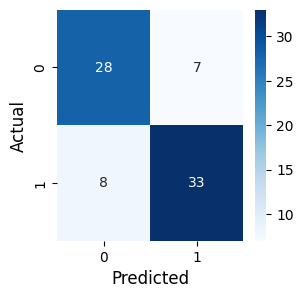

In [56]:
cf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=[3,3])
sns.heatmap(cf_matrix, annot=True, cmap='Blues')
plt.xlabel('Predicted', fontsize=12)
plt.ylabel('Actual', fontsize=12)
plt.show()

In [57]:
28+7+33+8

76

In [58]:
(28+33)/(28+33+7+8)

0.8026315789473685

In [59]:
# precision= true positive/(true positive+false positive)




In [60]:
33/(33+7)

0.825

In [61]:
# recall= true positive/(true positive+ false negative)

In [62]:
33/(33+8)


0.8048780487804879

The base model has learned the training data very well, but it does not generalize as well on new input data (test set). In technical terms, our base model is overfitting. Decision tree models have a tendency to overfit.

Let's use Grid Search and Random Search methods to improve our model's performance (test accuracy score)

####  I think you should make the distinction between a leaf (also called external node) and an internal node. An internal node will have further splits (also called children), while a leaf is by definition a node without any children (without any further splits).

#### min_samples_split specifies the minimum number of samples required to split an internal node, while min_samples_leaf specifies the minimum number of samples required to be at a leaf node.

### Set up hyperparameter grid

In [63]:
# Prepare the hyperparameters values to search
max_depth = [int(x) for x in np.linspace(2, 20, num = 10)]
min_samples_leaf = np.arange(2, 15, 2)
min_samples_split = [2, 3, 5, 7, 10]

# Create the hyperparameter grid
grid = {'max_depth': max_depth,
        'min_samples_split': min_samples_split,
        'min_samples_leaf': min_samples_leaf
       }

pprint(grid)

{'max_depth': [2, 4, 6, 8, 10, 12, 14, 16, 18, 20],
 'min_samples_leaf': array([ 2,  4,  6,  8, 10, 12, 14]),
 'min_samples_split': [2, 3, 5, 7, 10]}


In [64]:
10*7*5

350

* 10  7  5=350

In [65]:
# Instantiate the grid search model
#  Note: cv=10
gs = GridSearchCV(model, param_grid=grid,
                  scoring="accuracy", verbose=1,
                  n_jobs=-1, cv=10, return_train_score=True)

### Run grid search

In [66]:
%%time
gs.fit(X_train, y_train)

Fitting 10 folds for each of 350 candidates, totalling 3500 fits
CPU times: user 2.61 s, sys: 115 ms, total: 2.73 s
Wall time: 49.5 s


GridSearchCV(cv=10, estimator=DecisionTreeClassifier(random_state=42),
             n_jobs=-1,
             param_grid={'max_depth': [2, 4, 6, 8, 10, 12, 14, 16, 18, 20],
                         'min_samples_leaf': array([ 2,  4,  6,  8, 10, 12, 14]),
                         'min_samples_split': [2, 3, 5, 7, 10]},
             return_train_score=True, scoring='accuracy', verbose=1)

We tried all 350 hyperparameter combinations times 10 folds for each combination resulting in 3500 trained models

### Review best parameters and accuracy score from grid search

In [67]:
print("Optimal hyperparameter combination:", gs.best_params_)
print("\nMean cross-validated training accuracy score:", np.round(gs.best_score_,4))

Optimal hyperparameter combination: {'max_depth': 4, 'min_samples_leaf': np.int64(12), 'min_samples_split': 2}

Mean cross-validated training accuracy score: 0.8069


### Re-train model with best hyperparameters from grid search

In [68]:
# Train with gs.best_params_ from cell above
gs.best_estimator_.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=4, min_samples_leaf=np.int64(12),
                       random_state=42)

### Review best grid search estimator's predictions on the test data

In [69]:
y_pred = gs.best_estimator_.predict(X_test)     # Make predictions on test set
grid_search_test_accuracy = np.round(accuracy_score(y_test, y_pred), 4)
print("Test accuracy:", np.round(accuracy_score(y_test, y_pred), 4))

Test accuracy: 0.8158


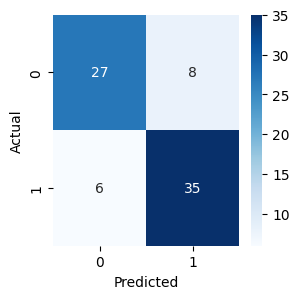

In [70]:
cf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=[3,3])
sns.heatmap(cf_matrix, annot=True, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Model performance has improved. This time, the model is not overfitting as much. It performs almost as well on both train and test sets (80.69% vs. 81.58%). In addition to that, both false positives and false negatives have slightly reduced after tuning hyperparameters.

### Set up random search

In [71]:
# Use the same hyperparameter grid
#  Notes: cv=10 (same as for grid search), and n_iter=50
rs = RandomizedSearchCV(model, param_distributions=grid,
                        n_iter=100, scoring="accuracy", random_state=RANDOM_STATE,
                        n_jobs=-1, cv=10, return_train_score=True)

### Run random search

In [72]:
%%time
rs.fit(X_train, y_train)

CPU times: user 606 ms, sys: 12.9 ms, total: 619 ms
Wall time: 7.5 s


RandomizedSearchCV(cv=10, estimator=DecisionTreeClassifier(random_state=42),
                   n_iter=100, n_jobs=-1,
                   param_distributions={'max_depth': [2, 4, 6, 8, 10, 12, 14,
                                                      16, 18, 20],
                                        'min_samples_leaf': array([ 2,  4,  6,  8, 10, 12, 14]),
                                        'min_samples_split': [2, 3, 5, 7, 10]},
                   random_state=42, return_train_score=True,
                   scoring='accuracy')

We tried a randomly selected set of 50 hyperparameter combinations times 10 folds for each combination resulting in 500 trained models

### Review best parameters and accuracy score from random search

In [73]:
print("Optimal hyperparameter combination:", rs.best_params_)
print("\tNote: Different combination of hyperparameter values than from grid search")
print("\nMean cross-validated training accuracy score:", np.round(rs.best_score_,4))

Optimal hyperparameter combination: {'min_samples_split': 3, 'min_samples_leaf': np.int64(12), 'max_depth': 20}
	Note: Different combination of hyperparameter values than from grid search

Mean cross-validated training accuracy score: 0.8069


### Re-train model with best hyperparameters from random search

In [74]:
# Train with rs.best_params_ from cell above
rs.best_estimator_.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=20, min_samples_leaf=np.int64(12),
                       min_samples_split=3, random_state=42)

### Review best random search estimator's predictions

In [75]:
y_pred = rs.best_estimator_.predict(X_test)     # Make predictions on test set
random_search_test_accuracy = np.round(accuracy_score(y_test, y_pred), 4)
print("Test accuracy:", np.round(accuracy_score(y_test, y_pred), 4))

Test accuracy: 0.8158


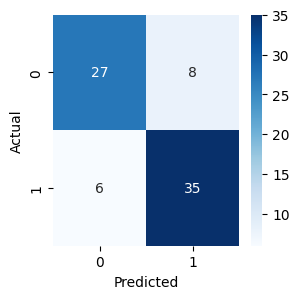

In [76]:
cf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=[3,3])
sns.heatmap(cf_matrix, annot=True, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### Performance summary

In [77]:
print("Test accuracy")
print("=============")
print("Initial model =", initial_test_accuracy)
print("After grid search =", grid_search_test_accuracy)
print("After random search =", random_search_test_accuracy)

Test accuracy
Initial model = 0.8026
After grid search = 0.8158
After random search = 0.8158
